# Crecimiento mandibular

En la clase 4 ajustamos rectas diferentes para distintos grupos. En la notebook anterior
vimos cómo compartir información entre grupos mediante una distribución común. Ahora vamos
a combinar esas dos ideas para estudiar trayectorias de crecimiento.

Vamos a comparar cuatro modelos normales:

1. Una media común, sin covariables.
2. Una recta común: agrupamiento completo de los coeficientes.
3. Una recta por niño, con _priors_ de parámetros fijos: sin agrupamiento de los coeficientes.
4. Una recta por niño, con distribuciones poblacionales: agrupamiento parcial de los coeficientes.

Nos interesa ver cómo cambian las estimaciones y su incertidumbre al compartir información,
y cómo describimos el crecimiento de los niños observados.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pymc as pm

from pymc.model.fgraph import clone_model

plt.rcParams["axes.prop_cycle"] = plt.cycler(
    color=["#0072B2", "#E69F00", "#009E73", "#CC79A7"]
)
az.rcParams["stats.ci_prob"] = 0.95

In [2]:
# Resume las medias y mediciones que generó PyMC para los niños elegidos.
def graficar_trayectorias(predicciones, edades_grid, nino_grid, datos, elegidos=(1, 9, 12)):
    fig, axes = plt.subplots(1, len(elegidos), figsize=(11, 3.5), sharey=True, layout="constrained")

    for ax, nino in zip(axes, elegidos):
        pred_nino = predicciones.isel(obs=nino_grid == nino - 1)
        mu_media = pred_nino["mu"].mean(dim=("chain", "draw"))
        mu_inferior, mu_superior = pred_nino["mu"].quantile(
            [0.025, 0.975], dim=("chain", "draw")
        )
        y_inferior, y_superior = pred_nino["altura"].quantile(
            [0.025, 0.975], dim=("chain", "draw")
        )
        ax.fill_between(edades_grid, y_inferior, y_superior, color="C0", alpha=0.15)
        ax.fill_between(edades_grid, mu_inferior, mu_superior, color="C0", alpha=0.45)
        ax.plot(edades_grid, mu_media, color="C0")
        observadas = datos.filter(pl.col("nino") == nino)
        ax.scatter(observadas["edad"], observadas["altura"], color="0.4", s=20, alpha=0.7)
        ax.set(title=f"Niño {nino}", xlabel="Edad (años)")
    axes[0].set_ylabel("Altura mandibular (mm)")

    return fig, axes

## Los datos

Tenemos mediciones de la altura de la rama mandibular, en milímetros, de veinte varones
a los 8, 8.5, 9 y 9.5 años. Cada niño aporta cuatro visitas, de modo que hay ochenta observaciones.

**¿Cómo cambia la altura mandibular con la edad y cuánto difiere el crecimiento entre niños?**

Los datos provienen del estudio de Elston y Grizzle (1962).

**Referencia:** Elston, R. C. y Grizzle, J. E. (1962).
[Estimation of Time-Response Curves and Their Confidence Bands](https://doi.org/10.2307/2527453).
*Biometrics*, 18(2), 148–159.

In [3]:
datos_mandibula = pl.read_csv("../datos/mandibula.csv")
datos_mandibula

nino,edad,altura
i64,f64,f64
1,8.0,47.8
1,8.5,48.8
1,9.0,49.0
1,9.5,49.7
2,8.0,46.4
…,…,…
19,9.5,48.4
20,8.0,46.3
20,8.5,47.6


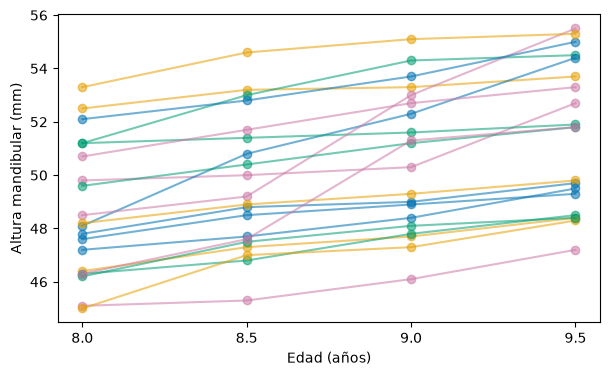

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for _, observadas in datos_mandibula.group_by("nino", maintain_order=True):
    ax.plot(observadas["edad"], observadas["altura"], marker="o", alpha=0.55)
ax.set(xlabel="Edad (años)", ylabel="Altura mandibular (mm)", xticks=[8, 8.5, 9, 9.5]);

## Modelo 1: normal sin covariables

Empezamos con una sola normal para las ochenta observaciones. Usamos $i=1,\ldots,80$
para identificar las filas de `datos_mandibula`: $Y_i$ es la altura mandibular de la observación $i$.

$$
\begin{aligned}
Y_i\mid \mu, \sigma &\sim \operatorname{Normal}(\mu,\sigma^2), \\
\mu &\sim \operatorname{Normal}(50,10^2), \\
\sigma &\sim \operatorname{HalfNormal}(5).
\end{aligned}
$$

$\mu$ es la media común y $\sigma$ es el desvío residual. El modelo supone la misma distribución
a cualquier edad y para cualquier niño, con observaciones independientes dados esos parámetros.

El _prior_ de $\mu$ asigna aproximadamente un 95% de probabilidad a medias entre 30 y 70 mm.
La escala de 5 mm de la seminormal permite una dispersión amplia alrededor de esa media.

En el código, `altura_obs` contiene las alturas y la dimensión `obs` identifica sus posiciones,
numeradas de 0 a 79 en Python.

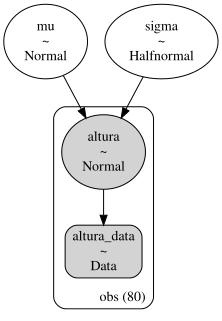

In [5]:
altura_obs = datos_mandibula["altura"].to_numpy()
coords = {"obs": np.arange(altura_obs.size)}

with pm.Model(coords=coords) as modelo_1:
    altura_data = pm.Data("altura_data", altura_obs, dims="obs")
    mu = pm.Normal("mu", mu=50, sigma=10)
    sigma = pm.HalfNormal("sigma", sigma=5)
    pm.Normal("altura", mu=mu, sigma=sigma, observed=altura_data, dims="obs")

modelo_1.to_graphviz()

In [6]:
with modelo_1:
    idata_1 = pm.sample(chains=4, random_seed=2026)

NUTS[nutpie]: [mu, sigma]


Output()

In [7]:
az.summary(idata_1, var_names=["mu", "sigma"], round_to=2)

,mean,sd,eti95_lb,eti95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu,50.08,0.32,49.45,50.70,3963.62,2744.93,1.0,0.01,0.01
sigma,2.80,0.23,2.39,3.31,3802.58,2720.59,1.0,0.00,0.00


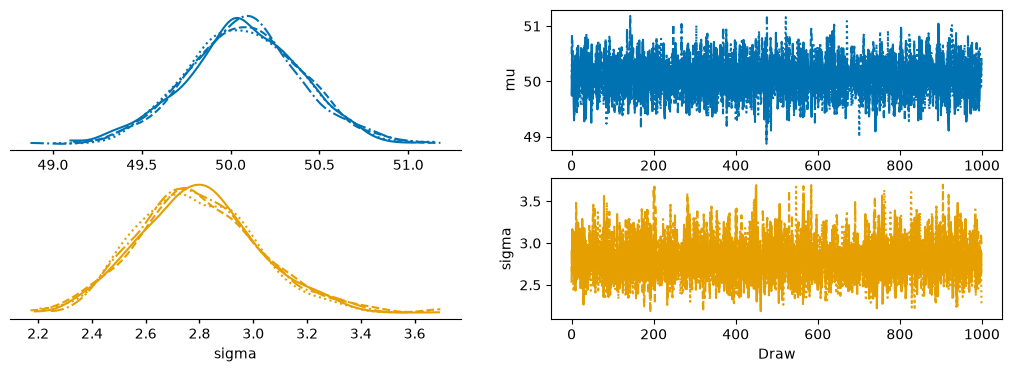

In [8]:
az.plot_trace_dist(idata_1, var_names=["mu", "sigma"]);

Grafiquemos la media _a posteriori_ y los intervalos centrales del 95% para la media y para
una nueva medición. Como en la clase 4, usamos una copia del modelo para predecir.
Reemplazamos `altura_data` por `[0.0]` para indicar que queremos una sola medición:
ese cero es un marcador y su valor no interviene en la predicción.

Sampling: [altura]


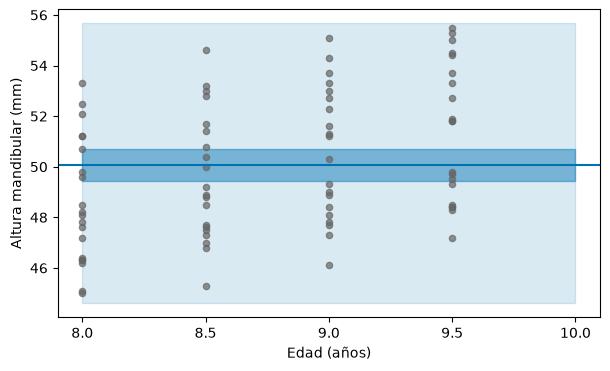

In [9]:
with clone_model(modelo_1):
    pm.set_data({"altura_data": [0.0]}, coords={"obs": [0]})
    pred_1 = pm.sample_posterior_predictive(
        idata_1, var_names=["mu", "altura"], predictions=True,
        random_seed=2026, progressbar=False,
    )

edades_grid_1 = np.linspace(8, 10, 81)
mu_1 = pred_1["predictions"]["mu"]
altura_pred_1 = pred_1["predictions"]["altura"].isel(obs=0)
mu_inferior_1, mu_superior_1 = mu_1.quantile([0.025, 0.975], dim=("chain", "draw"))
y_inferior_1, y_superior_1 = altura_pred_1.quantile([0.025, 0.975], dim=("chain", "draw"))
edad_obs = datos_mandibula["edad"].to_numpy()

fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(edades_grid_1, y_inferior_1.item(), y_superior_1.item(), color="C0", alpha=0.15)
ax.fill_between(edades_grid_1, mu_inferior_1.item(), mu_superior_1.item(), color="C0", alpha=0.45)
ax.axhline(mu_1.mean().item(), color="C0")
ax.scatter(edad_obs, altura_obs, color="0.4", s=20, alpha=0.7)
ax.set(xlabel="Edad (años)", ylabel="Altura mandibular (mm)", xticks=[8, 8.5, 9, 9.5, 10]);

La línea y las bandas son horizontales porque el modelo no usa la edad y, por lo tanto, predice lo mismo para cualquier edad.
La banda oscura muestra la incertidumbre sobre $\mu$ y la banda clara incorpora además la variación de las mediciones, cuya varianza es $\sigma^2$.

Los puntos muestran que las alturas aumentan con la edad, un patrón que este modelo no describe.

## Modelo 2: edad, intercepto y pendiente comunes

Para describir el aumento de altura con la edad, agregamos una pendiente común.
Usamos $x_i=\operatorname{edad}_i-8$, de modo que el intercepto describe la altura esperada
a los ocho años. Es un modelo de **agrupamiento completo** de los coeficientes de la recta.

$$
\begin{aligned}
Y_i &\sim \operatorname{Normal}(\alpha+\beta x_i,\sigma^2), \\
\alpha &\sim \operatorname{Normal}(50,10^2), \\
\beta &\sim \operatorname{Normal}(0,3^2), \\
\sigma &\sim \operatorname{HalfNormal}(3^2).
\end{aligned}
$$

$\alpha$ es el intercepto, en milímetros, y $\beta$ es la pendiente, en mm/año.
El _prior_ de $\beta$ asigna aproximadamente un 95% de probabilidad a pendientes entre
$-6$ y $6$ mm/año, sin favorecer un signo. Para $\sigma$ usamos ahora una escala de 3 mm:
asignamos aproximadamente un 95% de probabilidad a desvíos menores que 6 mm una vez
incorporada la edad. Este _prior_ se conserva en los modelos 3 y 4.

En el código, `x_edad` contiene las edades centradas y `mu` guarda las medias
$\mu_i=\alpha+\beta x_i$, en el mismo orden que `altura_obs`.

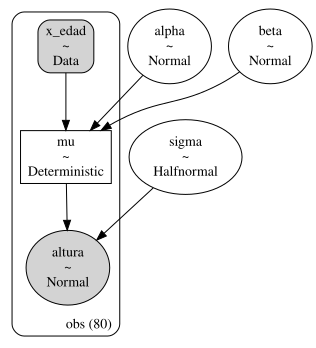

In [10]:
x_edad = datos_mandibula["edad"].to_numpy() - 8

with pm.Model(coords=coords) as modelo_2:
    x_data = pm.Data("x_edad", x_edad, dims="obs")
    alpha = pm.Normal("alpha", mu=50, sigma=10)
    beta = pm.Normal("beta", mu=0, sigma=3)
    sigma = pm.HalfNormal("sigma", sigma=3)
    mu = pm.Deterministic("mu", alpha + beta * x_data, dims="obs")
    pm.Normal("altura", mu=mu, sigma=sigma, observed=altura_obs, dims="obs")

modelo_2.to_graphviz()

In [11]:
with modelo_2:
    idata_2 = pm.sample(chains=4, random_seed=2026)

NUTS[nutpie]: [alpha, beta, sigma]


Output()

In [12]:
az.summary(idata_2, var_names=["alpha", "beta", "sigma"])

,mean,sd,eti95_lb,eti95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha,48.71,0.49,48,50,1407,1723,1.00,0.013,0.0087
beta,1.81,0.51,0.81,2.8,1366,1925,1.00,0.014,0.0094
sigma,2.605,0.211,2.2,3.1,2816,2833,1.00,0.004,0.0035


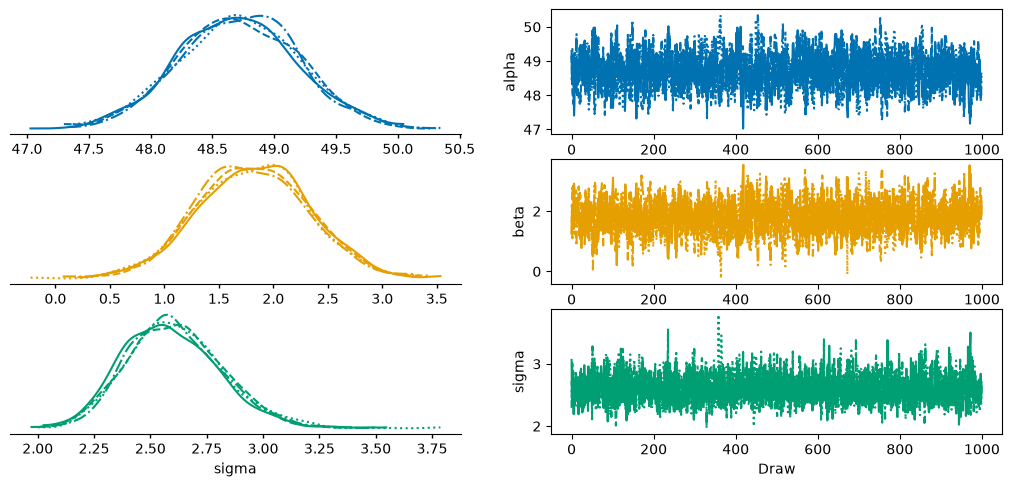

In [13]:
az.plot_trace_dist(idata_2, var_names=["alpha", "beta", "sigma"]);

In [14]:
(idata_2["posterior"]["beta"] > 0).mean().item() # Probabilidad de que la pendiente sea positiva

0.9995

Para visualizar las trayectorias, reemplazamos `x_edad` por una grilla de edades en una copia
del modelo y actualizamos las coordenadas de `obs`. Pedimos `mu` para las medias y `altura`
para las nuevas mediciones. Repetimos la grilla para cada niño para poder comparar los modelos
con los mismos paneles.

In [15]:
edades_grid = np.linspace(8, 10, 81)
ninos = datos_mandibula["nino"].unique(maintain_order=True).to_numpy()
n_ninos = len(ninos)
x_grid_ninos = np.tile(edades_grid - 8, n_ninos)
nino_grid = np.repeat(np.arange(n_ninos), len(edades_grid))
coords_grid = {"obs": np.arange(len(x_grid_ninos))}

with clone_model(modelo_2):
    pm.set_data({"x_edad": x_grid_ninos}, coords=coords_grid)
    pred_2 = pm.sample_posterior_predictive(
        idata_2, var_names=["mu", "altura"], predictions=True,
        random_seed=2026, progressbar=False,
    )

Sampling: [altura]


Mostremos las bandas centrales del 95% para la media (oscura) y para una nueva medición (clara)
en tres niños. Usaremos los mismos niños en los modelos siguientes.

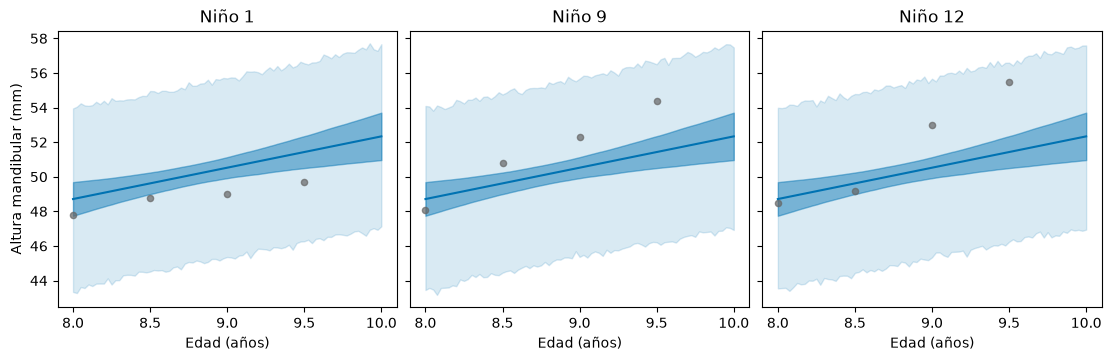

In [16]:
graficar_trayectorias(pred_2["predictions"], edades_grid, nino_grid, datos_mandibula);

Las rectas y las bandas son iguales en los tres paneles porque los coeficientes son comunes.
El modelo describe el aumento con la edad, pero las diferencias entre niños quedan en el residuo
y las bandas predictivas son amplias.

## Modelo 3: intercepto y pendiente por niño, sin jerarquía

Para describir las diferencias individuales, permitimos que cada niño tenga su propio intercepto y su propia pendiente.

Usamos $j=1,\ldots,20$ para los niños y $g(i)$ para indicar a cuál pertenece la observación $i$.
La media se calcula con los coeficientes de ese niño:

$$
\begin{aligned}
Y_i &\sim \operatorname{Normal}(\alpha_{g(i)}+\beta_{g(i)} x_i,\sigma^2), \\
\alpha_j &\sim \operatorname{Normal}(50,10^2), \\
\beta_j &\sim \operatorname{Normal}(0,3^2), \\
\sigma &\sim \operatorname{HalfNormal}(3^2).
\end{aligned}
$$

Los coeficientes tienen _priors_ independientes con parámetros fijos. Por eso hablamos de
un modelo **sin agrupamiento** de los coeficientes.

En el código, `alpha` y `beta` tienen veinte elementos. `nino_idx` traduce $g(i)$ a posiciones
de Python, de 0 a 19. Así, `alpha[nino_data] + beta[nino_data] * x_data` selecciona los
coeficientes correspondientes y produce una media por observación.

Al predecir cambiamos juntos `x_edad` y `nino_idx`, con una entrada por combinación de niño y edad.

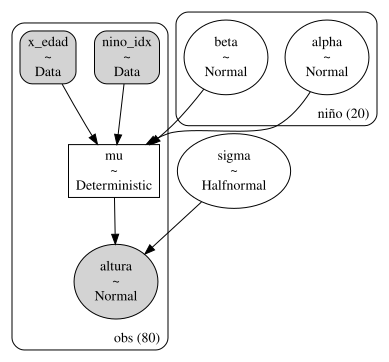

In [17]:
nino_idx = datos_mandibula["nino"].to_numpy() - 1
coords = {**coords, "niño": ninos}

with pm.Model(coords=coords) as modelo_3:
    x_data = pm.Data("x_edad", x_edad, dims="obs")
    nino_data_idx = pm.Data("nino_idx", nino_idx, dims="obs")
    alpha = pm.Normal("alpha", mu=50, sigma=10, dims="niño")
    beta = pm.Normal("beta", mu=0, sigma=3, dims="niño")
    sigma = pm.HalfNormal("sigma", sigma=3)
    mu = pm.Deterministic("mu", alpha[nino_data_idx] + beta[nino_data_idx] * x_data, dims="obs")
    pm.Normal("altura", mu=mu, sigma=sigma, observed=altura_obs, dims="obs")

modelo_3.to_graphviz()

In [18]:
with modelo_3:
    idata_3 = pm.sample(chains=4, random_seed=2026)

NUTS[nutpie]: [alpha, beta, sigma]


Output()

El _traceplot_ reúne las veinte distribuciones de $\alpha$ y las veinte de $\beta$.

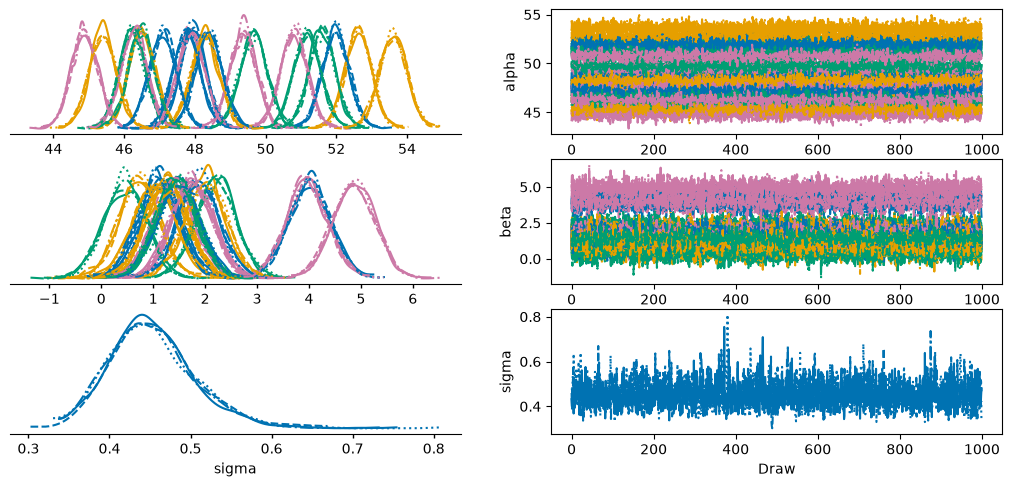

In [19]:
az.plot_trace_dist(idata_3, var_names=["alpha", "beta", "sigma"]);

Revisemos los resúmenes y diagnósticos de los coeficientes individuales y del desvío residual.

In [20]:
az.summary(idata_3, var_names=["alpha", "beta", "sigma"])

,mean,sd,eti95_lb,eti95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha[1],47.95,0.37,47,49,4364,3036,1.00,0.0056,0.0061
alpha[2],46.51,0.37,46,47,4716,2629,1.00,0.0055,0.0065
alpha[3],46.24,0.38,46,47,5227,2752,1.00,0.0052,0.0066
alpha[4],44.88,0.38,44,46,4909,2952,1.00,0.0054,0.0059
alpha[5],47.76,0.38,47,49,4764,3016,1.00,0.0055,0.006
alpha[6],52.63,0.37,52,53,4963,2808,1.00,0.0053,0.0063
alpha[7],51.6,0.38,51,52,4897,3195,1.00,0.0054,0.0059
alpha[8],49.37,0.38,49,50,4244,2973,1.00,0.0058,0.0073
alpha[9],48.4,0.38,48,49,4584,3166,1.00,0.0056,0.0061
alpha[10],45.4,0.39,45,46,5370,3354,1.00,0.0053,0.0066


Veamos las trayectorias y sus bandas para los mismos niños.

Sampling: [altura]


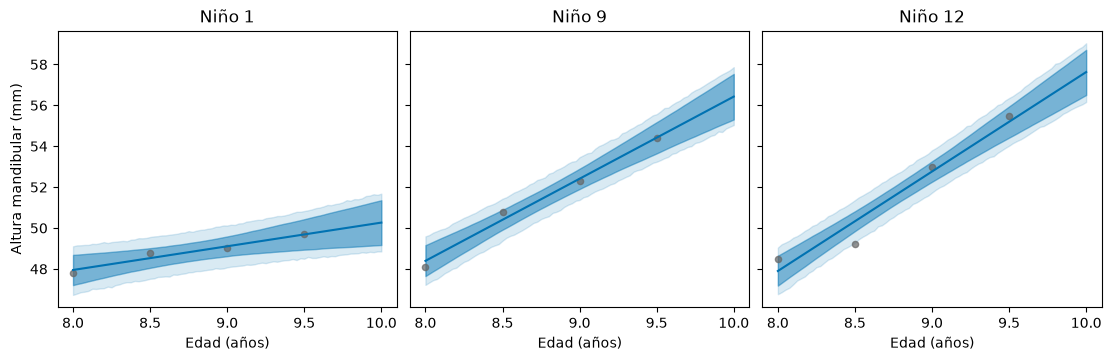

In [21]:
with clone_model(modelo_3):
    pm.set_data(
        {"x_edad": x_grid_ninos, "nino_idx": nino_grid},
        coords=coords_grid,
    )
    pred_3 = pm.sample_posterior_predictive(
        idata_3, var_names=["mu", "altura"], predictions=True,
        random_seed=2026, progressbar=False,
    )

graficar_trayectorias(pred_3["predictions"], edades_grid, nino_grid, datos_mandibula);

Las rectas ahora siguen las diferencias de altura inicial y de crecimiento entre niños.
Las bandas predictivas son más angostas que en el modelo 2. Sin embargo, cada recta se estima
con apenas cuatro visitas: nos interesa revisar cuánto dependen sus coeficientes de esas pocas mediciones.

## Modelo 4: intercepto y pendiente por niño, jerárquicos

Para estimar cada recta con información de los demás niños, retomamos el **agrupamiento parcial**
de la notebook anterior. Los interceptos provienen de una distribución poblacional y las pendientes,
de otra. Sus medias y desvíos ahora son desconocidos y se aprenden con los datos de todos los niños.

$$
\begin{aligned}
Y_i &\sim \operatorname{Normal}(\alpha_{g(i)}+\beta_{g(i)} x_i,\sigma^2), \\
\alpha_j &\sim \operatorname{Normal}(\mu_\alpha,\tau_\alpha^2), \\
\beta_j &\sim \operatorname{Normal}(\mu_\beta,\tau_\beta^2), \\
\mu_\alpha &\sim \operatorname{Normal}(50,10^2), \\
\mu_\beta &\sim \operatorname{Normal}(0,3^2), \\
\tau_\alpha &\sim \operatorname{HalfNormal}(5^2), \\
\tau_\beta &\sim \operatorname{HalfNormal}(2^2), \\
\sigma &\sim \operatorname{HalfNormal}(3^2).
\end{aligned}
$$

$\mu_\alpha$ es la altura media poblacional a los ocho años, en milímetros, y $\mu_\beta$,
el crecimiento medio, en mm/año. $\tau_\alpha$ y $\tau_\beta$ describen la dispersión entre
los interceptos y entre las pendientes. Sus _priors_ tienen escalas de 5 mm y 2 mm/año,
respectivamente, que permiten diferencias entre las rectas individuales. $\sigma$ conserva
el mismo significado y _prior_ que en los modelos 2 y 3.

Dados los parámetros poblacionales, suponemos que el intercepto y la pendiente de un niño
son independientes. No incorporamos una asociación poblacional entre altura inicial y velocidad
de crecimiento. Esto no impide que ambos coeficientes estén relacionados _a posteriori_
al ajustar las mediciones de un mismo niño.

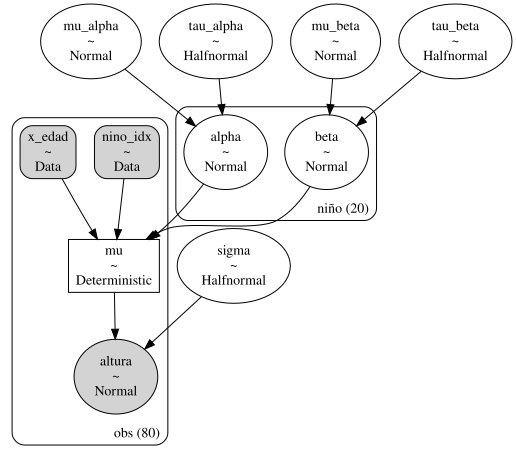

In [22]:
with pm.Model(coords=coords) as modelo_4:
    x_data = pm.Data("x_edad", x_edad, dims="obs")
    nino_data_idx = pm.Data("nino_idx", nino_idx, dims="obs")

    mu_alpha = pm.Normal("mu_alpha", mu=50, sigma=10)
    mu_beta = pm.Normal("mu_beta", mu=0, sigma=3)
    tau_alpha = pm.HalfNormal("tau_alpha", sigma=5)
    tau_beta = pm.HalfNormal("tau_beta", sigma=2)
    alpha = pm.Normal("alpha", mu=mu_alpha, sigma=tau_alpha, dims="niño")
    beta = pm.Normal("beta", mu=mu_beta, sigma=tau_beta, dims="niño")

    sigma = pm.HalfNormal("sigma", sigma=3)
    mu = pm.Deterministic("mu", alpha[nino_data_idx] + beta[nino_data_idx] * x_data, dims="obs")
    pm.Normal("altura", mu=mu, sigma=sigma, observed=altura_obs, dims="obs")

modelo_4.to_graphviz()

In [23]:
with modelo_4:
    idata_4 = pm.sample(chains=4, random_seed=2026)

NUTS[nutpie]: [mu_alpha, mu_beta, tau_alpha, tau_beta, alpha, beta, sigma]


Output()

Mostremos el resumen de los parámetros poblacionales y del desvío residual.

In [24]:
az.summary(idata_4, var_names=["mu_alpha", "mu_beta", "tau_alpha", "tau_beta", "sigma"])

,mean,sd,eti95_lb,eti95_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
mu_alpha,48.69,0.62,47,50,5610,2678,1.00,0.0084,0.012
mu_beta,1.854,0.29,1.3,2.4,4865,2877,1.00,0.0042,0.0057
tau_alpha,2.66,0.49,1.9,3.8,5277,2901,1.00,0.0072,0.01
tau_beta,1.15,0.226,0.79,1.7,4314,3185,1.00,0.0036,0.0037
sigma,0.458,0.053,0.37,0.57,1879,2317,1.00,0.0012,0.00091


En este ajuste también se revisaron los diagnósticos de los interceptos y las pendientes
individuales, sin encontrar problemas. Por brevedad, mostramos solo el resumen anterior.

### Incertidumbre y contracción de los coeficientes

Comparemos los modelos 3 y 4, primero para los interceptos y luego para las pendientes.
En cada gráfico mostramos las medias _a posteriori_ y los intervalos de credibilidad del 95%.
La línea vertical marca la media poblacional estimada por el modelo jerárquico.

Los puntos permiten ver la contracción (*shrinkage*) y los intervalos, cómo cambia la
incertidumbre de cada coeficiente. Un intervalo más angosto representa mayor precisión
dentro del modelo; no es necesario que todos se acorten al incorporar la jerarquía.

In [25]:
def graficar_coeficientes(idata_sin, idata_jer, parametro, poblacional, etiqueta):
    fig, ax = plt.subplots(figsize=(8, 7))
    ninos = idata_sin["posterior"][parametro].coords["niño"].to_numpy()
    for idata, desplazamiento, nombre in [
        (idata_sin, -0.15, "Sin jerarquía"),
        (idata_jer, 0.15, "Jerárquico"),
    ]:
        muestras = idata["posterior"][parametro].sel({"niño": ninos})
        media = muestras.mean(dim=("chain", "draw")).to_numpy()
        inferior, superior = muestras.quantile(
            [0.025, 0.975], dim=("chain", "draw")
        ).to_numpy()
        ax.errorbar(
            media, ninos + desplazamiento,
            xerr=[media - inferior, superior - media],
            fmt="o", capsize=3, label=nombre,
        )
    media_poblacional = idata_jer["posterior"][poblacional].mean().item()
    ax.axvline(media_poblacional, color="0.4", ls="--", label="Media poblacional (modelo jerárquico)")
    ax.set(xlabel=etiqueta, ylabel="Niño", yticks=ninos)
    ax.legend()
    return fig, ax

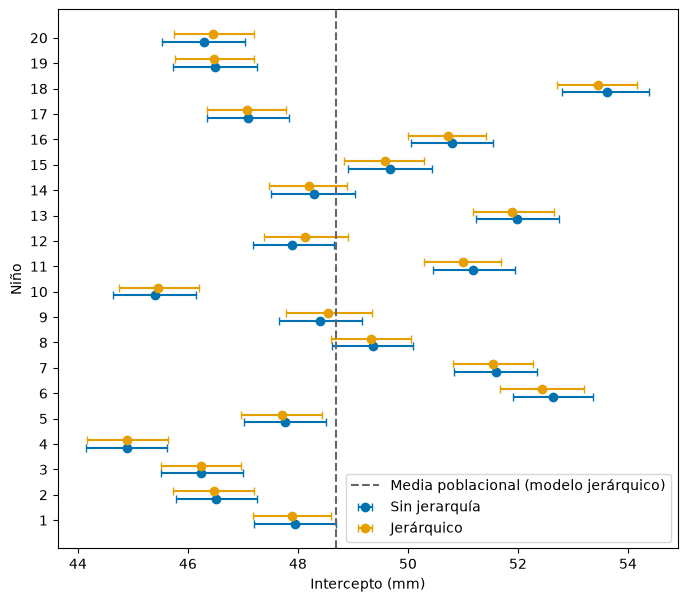

In [26]:
graficar_coeficientes(idata_3, idata_4, "alpha", "mu_alpha", "Intercepto (mm)");

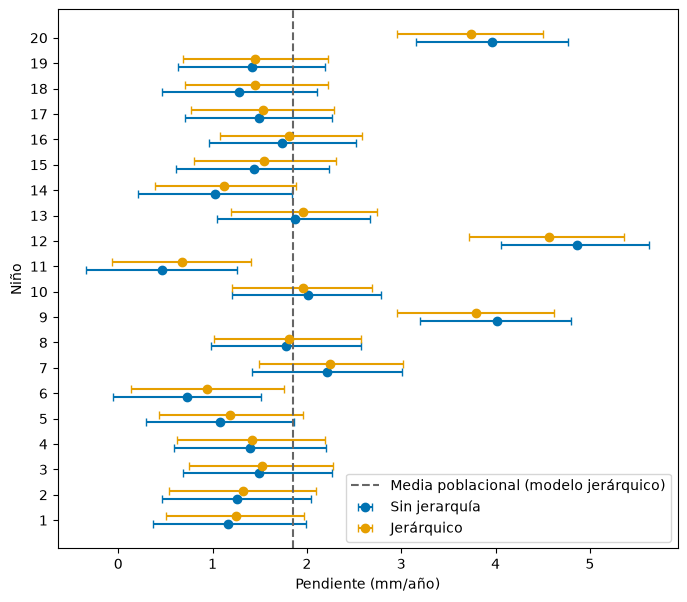

In [27]:
graficar_coeficientes(idata_3, idata_4, "beta", "mu_beta", "Pendiente (mm/año)");

Los intervalos de los interceptos cambian poco entre modelos. En las pendientes, el modelo
jerárquico produce intervalos algo más angostos y desplaza las medias más extremas hacia
el crecimiento poblacional. Podemos ver así que acercar una estimación a la media poblacional
y reducir su incertidumbre son cambios distintos.

Ahora ubiquemos las medias de ambos coeficientes en un mismo plano. Cada flecha va de la
estimación sin jerarquía (azul) a la jerárquica (naranja) del mismo niño. La cruz marca las
medias poblacionales. Este gráfico muestra los desplazamientos conjuntos; los intervalos
de los gráficos anteriores permiten evaluar su incertidumbre.

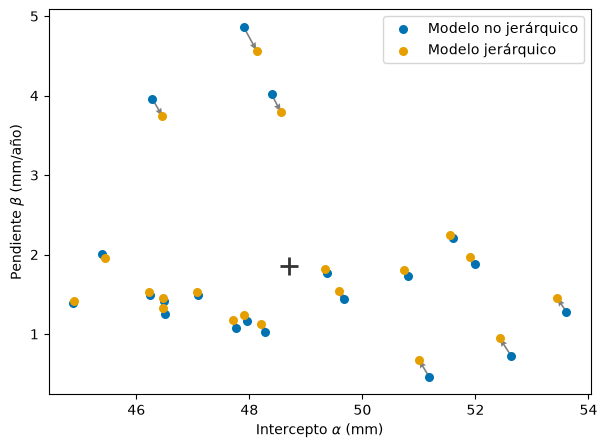

In [28]:
alpha_sin = idata_3["posterior"]["alpha"].mean(dim=("chain", "draw")).to_numpy()
beta_sin = idata_3["posterior"]["beta"].mean(dim=("chain", "draw")).to_numpy()
alpha_jer = idata_4["posterior"]["alpha"].mean(dim=("chain", "draw")).to_numpy()
beta_jer = idata_4["posterior"]["beta"].mean(dim=("chain", "draw")).to_numpy()
mu_alpha_media = idata_4["posterior"]["mu_alpha"].mean().item()
mu_beta_media = idata_4["posterior"]["mu_beta"].mean().item()

fig, ax = plt.subplots(figsize=(7, 5))
ax.quiver(
    alpha_sin, beta_sin, alpha_jer - alpha_sin, beta_jer - beta_sin,
    angles="xy", scale_units="xy", scale=1, color="0.5",
    width=0.003, headwidth=4, headlength=5, zorder=2,
)
ax.scatter(alpha_sin, beta_sin, color="C0", s=30, zorder=3, label="Modelo no jerárquico")
ax.scatter(alpha_jer, beta_jer, color="C1", s=30, zorder=3, label="Modelo jerárquico")
ax.scatter(mu_alpha_media, mu_beta_media, marker="+", color="0.2", s=160, linewidths=2, zorder=4)
ax.set(
    xlabel=r"Intercepto $\alpha$ (mm)",
    ylabel=r"Pendiente $\beta$ (mm/año)",
)
ax.legend();

Las flechas más visibles corresponden a pendientes alejadas de la media poblacional.
Los desplazamientos no tienen por qué apuntar directamente a la cruz: la información
disponible sobre cada coeficiente y su dependencia _a posteriori_ también intervienen.

A diferencia del ejemplo de hospitales, acá todos los niños tienen cuatro visitas a las mismas edades.
La contracción también aparece con un diseño equilibrado; su magnitud depende de la dispersión entre niños, de la precisión de las estimaciones y de los _priors_.

### Comparar el crecimiento medio

En el modelo 2 usamos una pendiente $\beta$ para todos los niños. En el modelo 4, cada niño
tiene su pendiente $\beta_j$ y $\mu_\beta$ es la media de la distribución poblacional.
Podemos comparar las distribuciones _a posteriori_ de $\beta$ y $\mu_\beta$ para ver cómo
cambia nuestra estimación del crecimiento medio al permitir diferencias individuales.

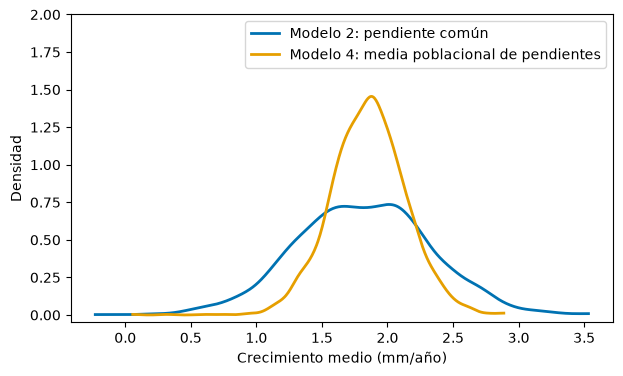

In [29]:
fig, ax = plt.subplots(figsize=(7, 4))
for muestras, etiqueta in [
    (idata_2["posterior"]["beta"], "Modelo 2: pendiente común"),
    (idata_4["posterior"]["mu_beta"], "Modelo 4: media poblacional de pendientes"),
]:
    grilla, densidad, _ = az.kde(muestras.to_numpy().ravel())
    ax.plot(grilla, densidad, label=etiqueta, lw=2)
ax.set(xlabel="Crecimiento medio (mm/año)", ylabel="Densidad", ylim=(-0.05, 2))
ax.legend();

Las medias _a posteriori_ son parecidas: alrededor de 1.82 mm/año en el modelo 2 y 1.85 mm/año
en el modelo 4. En estos datos, la distribución de $\mu_\beta$ es más concentrada.

El modelo jerárquico nos permite tener lo mejor de los dos mundos. Con $\mu_\beta$ podemos
estudiar el crecimiento medio poblacional, como hacíamos con la pendiente común del modelo 2
(_complete pooling_). A la vez, con las pendientes $\beta_j$ podemos describir el crecimiento
específico de cada niño, incorporando la información de los demás mediante la contracción
(_shrinkage_). Así obtenemos una estimación poblacional y estimaciones individuales que
comparten información.

### Volver a la pregunta inicial

Además del crecimiento medio, nos interesa cuánto difieren las velocidades entre niños.
La media _a posteriori_ de `tau_beta` es de unos 1.15 mm/año, con un intervalo central del 95%
de aproximadamente 0.79 a 1.70 mm/año. Este desvío describe la dispersión de las pendientes
individuales alrededor de `mu_beta`.

Consultemos también la probabilidad de que el crecimiento medio poblacional sea positivo.

In [30]:
(idata_4["posterior"]["mu_beta"] > 0).mean().item()

1.0

Al multiplicar las muestras de `mu_beta` por dos, obtenemos el cambio medio poblacional
entre los ocho y los diez años. Calculemos la mediana y un intervalo central del 95%.

In [31]:
cambio_poblacional = 2 * idata_4["posterior"]["mu_beta"]
cambio_poblacional.quantile([0.025, 0.5, 0.975]).to_numpy()

array([2.58391301, 3.71542734, 4.8466528 ])

Sampling: [altura]


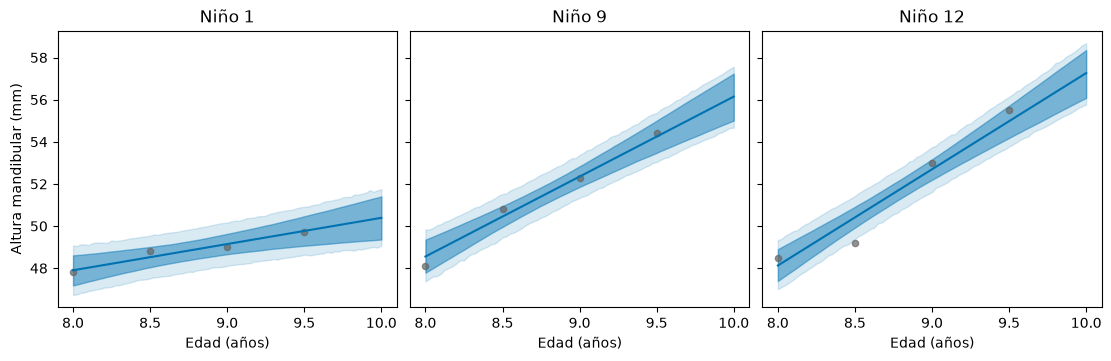

In [32]:
with clone_model(modelo_4):
    pm.set_data(
        {"x_edad": x_grid_ninos, "nino_idx": nino_grid},
        coords=coords_grid,
    )
    pred_4 = pm.sample_posterior_predictive(
        idata_4, var_names=["mu", "altura"], predictions=True,
        random_seed=2026, progressbar=False,
    )

graficar_trayectorias(pred_4["predictions"], edades_grid, nino_grid, datos_mandibula);

La grilla llega hasta los diez años, medio año después de la última visita observada.
En ese tramo dependemos de que la tendencia lineal siga describiendo el crecimiento.

Para consultar la altura de un niño conocido a los diez años, pasamos una edad centrada igual a 2
y el índice del niño elegido a `pm.set_data()` en una copia del modelo.

In [33]:
nino_pred = 9
umbral_altura = 55

with clone_model(modelo_4):
    pm.set_data(
        {"x_edad": [2.0], "nino_idx": [nino_pred - 1]},
        coords={"obs": [0]},
    )
    pred_10 = pm.sample_posterior_predictive(
        idata_4, var_names=["altura"], predictions=True,
        random_seed=2026, progressbar=False,
    )

altura_10 = pred_10["predictions"]["altura"].isel(obs=0)
altura_10.quantile([0.025, 0.5, 0.975], dim=("chain", "draw")).to_numpy()

Sampling: [altura]


array([54.62659402, 56.17868924, 57.56808048])

In [34]:
(altura_10 > umbral_altura).mean().item()

0.9395

### ¿Qué aspectos de las trayectorias reproduce el modelo?

Un chequeo global de alturas puede ocultar diferencias en el crecimiento. Comparemos la media
y el desvío de los cambios entre la primera y la última visita. El segundo resumen permite
revisar si el modelo reproduce cuánto difieren esos cambios entre niños.

En los histogramas, el azul corresponde a las réplicas y la línea naranja al valor observado.
Además, revisemos los residuos por edad, con una línea horizontal en cero como referencia.

Sampling: [altura]


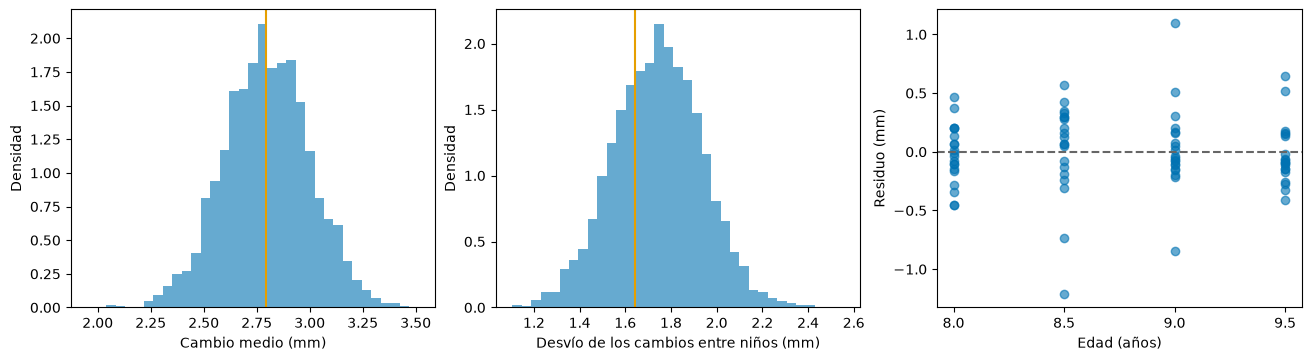

In [35]:
with modelo_4:
    ppc_4 = pm.sample_posterior_predictive(
        idata_4, var_names=["altura"], random_seed=2026, progressbar=False,
    )

# Las visitas de cada edad están en el mismo orden de niños.
cambios_observados = altura_obs[edad_obs == 9.5] - altura_obs[edad_obs == 8]
rep_4 = ppc_4["posterior_predictive"]["altura"]
cambios_rep_4 = (
    rep_4.isel(obs=edad_obs == 9.5).to_numpy()
    - rep_4.isel(obs=edad_obs == 8).to_numpy()
)
mu_obs_4 = idata_4["posterior"]["mu"].mean(dim=("chain", "draw")).to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout="constrained")
axes[0].hist(cambios_rep_4.mean(axis=-1).ravel(), bins=35, density=True, alpha=0.6)
axes[0].axvline(cambios_observados.mean(), color="C1")
axes[0].set(xlabel="Cambio medio (mm)", ylabel="Densidad")
axes[1].hist(cambios_rep_4.std(axis=-1, ddof=1).ravel(), bins=35, density=True, alpha=0.6)
axes[1].axvline(cambios_observados.std(ddof=1), color="C1")
axes[1].set(xlabel="Desvío de los cambios entre niños (mm)", ylabel="Densidad")
axes[2].scatter(edad_obs, altura_obs - mu_obs_4, alpha=0.6)
axes[2].axhline(0, color="0.4", ls="--")
axes[2].set(xlabel="Edad (años)", ylabel="Residuo (mm)", xticks=[8, 8.5, 9, 9.5]);

En ambos histogramas, el valor observado cae en una zona donde se concentran los valores simulados. El modelo logra reproducir tanto el crecimiento promedio como las diferencias de crecimiento entre niños, según estos resúmenes. 

Los residuos se distribuyen alrededor de cero, sin una tendencia clara con la edad y con una dispersión parecida en las cuatro edades. En este gráfico tampoco encontramos patrones que el modelo no haya logrado reproducir.

## Comparar la dispersión residual

Comparemos ahora los _posteriors_ de $\sigma$, el desvío de las mediciones alrededor de sus
medias esperadas. Cada curva muestra la incertidumbre sobre ese desvío bajo uno de los modelos.

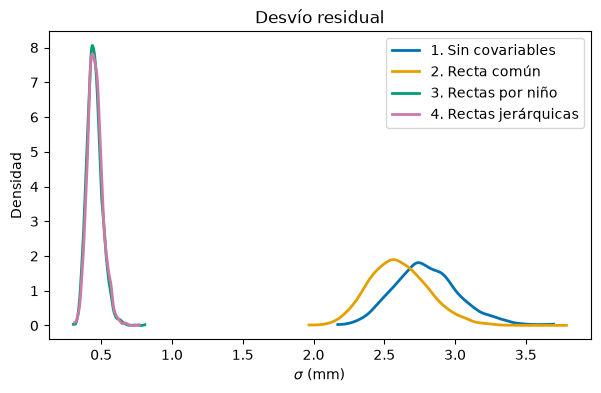

In [36]:
posteriors = [idata_1, idata_2, idata_3, idata_4]
etiquetas = ["1. Sin covariables", "2. Recta común", "3. Rectas por niño", "4. Rectas jerárquicas"]

fig, ax = plt.subplots(figsize=(7, 4))
for idata, etiqueta in zip(posteriors, etiquetas):
    muestras = idata["posterior"]["sigma"].to_numpy().flatten()
    grilla, densidad, _ = az.kde(muestras)
    ax.plot(grilla, densidad, label=etiqueta, lw=2)
ax.set(xlabel=r"$\sigma$ (mm)", ylabel="Densidad", title="Desvío residual")
ax.legend();

La media _a posteriori_ de $\sigma$ pasa de unos 2.8 mm sin covariables a 2.6 mm con una recta
común y a 0.45 mm con rectas individuales. La mayor reducción aparece al describir las diferencias
entre niños que antes quedaban en los residuos. Entre los modelos 1 y 2 también cambió su _prior_,
por lo que esa primera comparación no aísla el efecto de incorporar la edad.

Los modelos 3 y 4 tienen casi la misma dispersión residual. El aporte de la jerarquía se aprecia
en las estimaciones de los coeficientes y en la posibilidad de aprender distribuciones poblacionales.

## Reflexiones finales

El crecimiento medio estimado es de unos 1.85 mm/año, con diferencias entre las velocidades
de los niños. El modelo jerárquico permite estudiar ambos niveles: el crecimiento medio
poblacional y las trayectorias individuales, cuyos coeficientes se estiman compartiendo
información mediante la contracción (_shrinkage_).

### Evaluar la capacidad predictiva

En la clase 4 comparamos modelos mediante la densidad predictiva logarítmica esperada
(*expected log pointwise predictive density*, ELPD). Acá también podríamos estimar su
capacidad predictiva, teniendo en cuenta que cada niño aporta varias visitas.

Si dejamos afuera una visita, las otras mediciones de ese niño siguen disponibles.
Si queremos evaluar la predicción de un niño que no participó del ajuste, necesitamos dejar
afuera sus cuatro visitas. Repetir ese procedimiento para cada niño se conoce como validación
cruzada dejando un grupo afuera (*leave-one-group-out*, LOGO).

ArviZ permite organizar esos reajustes con
[`loo_kfold`](https://python.arviz.org/projects/stats/en/stable/api/generated/arviz_stats.loo_kfold.html).
Esa evaluación queda fuera del alcance de esta clase.

## Extensiones opcionales

### Revisar la dependencia entre visitas

En el chequeo de residuos miramos si quedaban diferencias sistemáticas por edad. También podríamos
revisar su secuencia dentro de cada niño. Aunque las visitas comparten el intercepto y la pendiente,
el modelo supone que sus errores son independientes una vez conocida esa recta.

Si una medición por encima de la recta suele ir seguida de otra también por encima, podríamos agregar
una estructura autorregresiva de orden uno (*first-order autoregressive*, AR(1)) para los residuos.
Esto permitiría describir una dependencia entre visitas que la recta todavía no explica.

### Relacionar el intercepto y la pendiente

Si quisiéramos conocer la relación entre la altura esperada a los ocho años y la velocidad de
crecimiento en la población, podríamos ampliar el modelo 4. Para eso, reemplazaríamos las dos
normales poblacionales independientes por una normal bivariada:

$$
\begin{pmatrix}\alpha_j\\\beta_j\end{pmatrix}
\sim \operatorname{Normal}_2\left(
\begin{pmatrix}\mu_\alpha\\\mu_\beta\end{pmatrix},
\begin{pmatrix}
\tau_\alpha^2 & \rho\tau_\alpha\tau_\beta\\
\rho\tau_\alpha\tau_\beta & \tau_\beta^2
\end{pmatrix}
\right).
$$

Esta extensión conserva las medias y los desvíos poblacionales que ya conocemos y agrega $\rho$,
la correlación entre interceptos y pendientes. Un valor positivo indicaría que los niños con mayor
altura inicial tienden a crecer más rápido, y uno negativo, que tienden a crecer más lento.
El modelo que ajustamos fija esa correlación en cero.

En PyMC, podríamos construir esta extensión con `pm.MvNormal()` y `pm.LKJCholeskyCov()`, usando
un _prior_ LKJ para la correlación. Su interpretación seguiría ligada al origen de la edad:
como usamos $x_i=\operatorname{edad}_i-8$, estaríamos relacionando la altura esperada a los ocho años
con la velocidad de crecimiento. Cambiar ese origen también cambia la correlación que estudiamos.